# Import Libraries

In [32]:
import os
import json
import re
import textwrap
import time
from typing import List, Optional, Dict, Any, TypedDict
from pdflatex import PDFLaTeX


# PDF extraction
import fitz  # PyMuPDF:to extract text from a PDF resume.  
# This handles multi-page PDFs and returns clean, concatenated text.

from pydantic import BaseModel, Field # forces LLM for clean output or structured data


from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END
print("All imports successful!")

All imports successful!


In [33]:

from dotenv import load_dotenv
load_dotenv()
GROQ_API_KEY = os.getenv("GROQ_API_KEY", "YOUR_GROQ_API_KEY_HERE")

# Define Groq LLM
llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    api_key=GROQ_API_KEY,
    temperature=0.2, # Low temp for consistent, factual generation
    max_tokens=8192 # defined limit for detailed responses
)

# Connectivit test
try:
    test_response = llm.invoke("Say 'Groq is Connected!' in exactly those words.")
    print(f"LLM Says: {test_response.content} ✅")
except Exception as e:
    print(f"Connection Failed: {e}")

Connection Failed: Error code: 429 - {'error': {'message': 'Rate limit reached for model `llama-3.3-70b-versatile` in organization `org_01kvwavvygfqsare33ns7rnzbe` service tier `on_demand` on tokens per day (TPD): Limit 100000, Used 97318, Requested 8239. Please try again in 1h20m1.248s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}


# Define the Pydantic Model

In [34]:
#  Resume Parser Output 

class ProjectDetail(BaseModel):
    """A single project from the resume."""
    name: str = Field(description="Project name or title")
    description: str = Field(description="Brief description of the project")
    technologies: List[str] = Field(default_factory=list, description="Technologies/tools used")
    highlights: List[str] = Field(default_factory=list, description="Key achievements or outcomes")

class ExperienceDetail(BaseModel):
    """A single work experience entry."""
    title: str = Field(description="Job title")
    company: str = Field(description="Company name")
    duration: str = Field(description="Employment period, e.g. 'Jan 2022 – Dec 2023'")
    bullet_points: List[str] = Field(default_factory=list, description="Responsibility/achievement bullet points")


class EducationDetail(BaseModel):
    """A single education entry."""
    degree: str = Field(description="Degree name, e.g. 'B.Tech in Computer Science'")
    institution: str = Field(description="University or school name")
    year: str = Field(default="", description="Graduation year or period")
    gpa: Optional[str] = Field(default=None, description="GPA or percentage if mentioned")


class ResumeData(BaseModel):
    """Structured representation of a parsed resume."""
    skills: List[str] = Field(default_factory=list, description="Technical and soft skills")
    projects: List[ProjectDetail] = Field(default_factory=list, description="Projects")
    experience: List[ExperienceDetail] = Field(default_factory=list, description="Work experience entries")
    education: List[EducationDetail] = Field(default_factory=list, description="Education entries")
    certifications: List[str] = Field(default_factory=list, description="Certifications or courses")


#  JD Parser Output 

class JDData(BaseModel):
    """Structured representation of a parsed job description."""
    required_skills: List[str] = Field(default_factory=list, description="Must-have skills")
    preferred_skills: List[str] = Field(default_factory=list, description="Nice-to-have skills")
    responsibilities: List[str] = Field(default_factory=list, description="Key responsibilities")
    experience_requirements: str = Field(default="", description="Experience level required, e.g. '3+ years'")


#  ATS Scoring Output 

class ScoreBreakdown(BaseModel):
    """Breakdown of the ATS score by category."""
    skill_match: float = Field(description="Score for skill overlap (0-100)")
    experience_alignment: float = Field(description="Score for years of experience and seniority alignment with the JD (0-100)")
    keyword_coverage: float = Field(description="Score for JD keyword presence in resume (0-100)")
    resume_quality: float = Field(description="Score for bullet-point clarity, action verbs, quantification (0-100)")
    project_relevance: float = Field(description="Score for how relevant projects are to the JD (0-100)")


class ATSScore(BaseModel):
    """ATS scoring result."""
    overall_score: float = Field(description="Weighted overall ATS score (0-100)")
    breakdown: ScoreBreakdown = Field(description="Category-wise score breakdown")
    reasoning: str = Field(default="", description="Brief explanation of the scoring")


#  Gap Analysis Output 

class GapAnalysis(BaseModel):
    """Result of comparing resume against the job description."""
    matched_skills: List[str] = Field(default_factory=list, description="Skills present in both resume and JD")
    missing_skills: List[str] = Field(default_factory=list, description="JD skills not found in the resume")
    missing_keywords: List[str] = Field(default_factory=list, description="Important JD keywords absent from resume")
    weak_areas: List[str] = Field(default_factory=list, description="Resume sections that need improvement")


#  Enhanced Resume Output 

class EnhancedBullet(BaseModel):
    """A single enhanced bullet point."""
    original: str = Field(description="The original bullet point from the resume")
    enhanced: str = Field(description="Improved version using STAR/XYZ format")
    section: str = Field(description="Which section this belongs to (experience, projects, etc.)")


class OptimizedResume(BaseModel):
    """Result of the resume enhancement agent."""
    enhanced_bullets: List[EnhancedBullet] = Field(default_factory=list, description="Improved bullet points")
    keywords_incorporated: List[str] = Field(default_factory=list, description="JD keywords woven into the enhanced text")
    optimization_summary: str = Field(default="", description="Summary of changes made")


#  Final Report Output 

class FinalReport(BaseModel):
    """The comprehensive final report combining all analysis."""
    ats_score_before: float = Field(description="ATS score before optimization")
    ats_score_after: float = Field(description="ATS score after optimization")
    improvement_percentage: float = Field(description="Percentage improvement")
    skill_match_analysis: Dict[str, List[str]] = Field(
        default_factory=dict,
        description="{'matched': [...], 'missing': [...]}"
    )
    missing_keywords: List[str] = Field(default_factory=list)
    enhanced_bullets: List[Dict[str, str]] = Field(default_factory=list)
    recommendations: List[str] = Field(default_factory=list, description="Actionable next steps")
    executive_summary: str = Field(default="", description="High-level summary paragraph")


#  LangGraph State 

class GraphState(TypedDict, total=False):
    """State object shared across all LangGraph nodes."""
    resume_text: str        # Raw text pulled from the resume Pdf
    jd_text: str            # Raw text pulled from the JD
    resume_data: dict       # LLM saves Structured, clean data after parsing the raw text using the Pydantic templates
    jd_data: dict           
    ats_score_before: dict  # This stores the initial calculation showing how poorly or well the original resume fits the job description before any changes are made.
    gap_analysis: dict      # master list of missing keywords, technical skills, and formatting red flags extracted by Groq
    optimized_resume: dict  # it saves the fresh, enhanced text blocks here.
    ats_score_after: dict   # new, higher score calculated after Groq finishes injecting the missing keywords
    final_report: dict      # feedback file showing the user a breakdown of what was changed
    optimized_latex: str    # ATS-optimized LaTeX source code


print("All Pydantic models and GraphState defined successfully! ✅")


All Pydantic models and GraphState defined successfully! ✅


# Resume Text Extraction

In [35]:
def extract_text_from_pdf(pdf_path: str) -> str:
    
    #Extract all text from a PDF file using PyMuPDF.

    if not os.path.exists(pdf_path): # Checks if resume actually exists on my pc
        raise FileNotFoundError(f"Resume PDF not found at: {pdf_path}")
    
    doc = fitz.open(pdf_path) # opens the pdf
    full_text = ""  # Creates empty text container
    
    for page_num in range(len(doc)): # loops for every page in pdf
        page = doc[page_num] # targets a single page
        full_text += page.get_text("text") # appends or attaches the newly gathered text
        full_text += "\n" #  breaks the line, so that multiple page wont mix up
    
    doc.close() 
    
    # Clean up excessive whitespace while preserving structure
    full_text = re.sub(r'\n{3,}', '\n\n', full_text) # Replaces the 3 or more than 3 consecutive Line breaks 2 line breaks
    full_text = full_text.strip() # remove trailing or leading spaces
    
    return full_text


#  Test with my resume 
RESUME_PDF_PATH = "Himakesh_Krishna_Resume.pdf"  # path of my resume

resume_text = extract_text_from_pdf(RESUME_PDF_PATH) # calling the function

print(f"📄 Extracted {len(resume_text)} characters from '{RESUME_PDF_PATH}'")
print("─" * 60)
print(resume_text[:500])

📄 Extracted 4838 characters from 'Himakesh_Krishna_Resume.pdf'
────────────────────────────────────────────────────────────
HIMAKESH KRISHNA 
+91 79797 77206  |  dr.himakesh@gmail.com  |  linkedin.com/in/himakesh-krishna  |  github.com/davidkumar355 
PROFESSIONAL SUMMARY 
Data Science practitioner (IIT Guwahati PG Certification, 2025–2026) with hands-on experience building end-to-end ML 
pipelines across NLP, computer vision, and unsupervised learning — including a 95% accuracy BBC News classifier, a 
95.52% CIFAR-10 model with Grad-CAM explainability, and a customer segmentation dashboard deployed on Streamlit. Six 


# JSON Parser
For clean and structured data extraction from LLM response.

In [36]:
def parse_json_from_response(response_text: str) -> dict:

    # Try to find JSON within ```json ... ``` code fences
    json_match = re.search(r'```(?:json)?\s*\n?(\{.*?\})\s*```', response_text, re.DOTALL)
    if json_match:
        return json.loads(json_match.group(1)) # returns clean JSON format into Dict
    

    # Try to find a raw JSON object, if the LLM did'nt return in markdown format
    json_match = re.search(r'(\{.*\})', response_text, re.DOTALL)
    if json_match:
        return json.loads(json_match.group(1))
    
    raise ValueError(f"Could not extract JSON from LLM response:\n{response_text[:500]}")


print("JSON parser helper defined.")

JSON parser helper defined.


# AGENT 1: Resume Parser Agent

This agent takes the raw resume text and extracts structured information

In [37]:
def resume_parser_agent(state: GraphState) -> dict:
    """
    LangGraph node: Parse resume text into structured ResumeData.
    """
    resume_text = state["resume_text"]
    
    system_prompt = """You are an expert resume parser. Extract structured information from the resume text.
Return ONLY a valid JSON object matching this exact schema (no extra text):

{
  "skills": ["skill1", "skill2", ...],
  "projects": [
    {
      "name": "Project Name",
      "description": "Brief description",
      "technologies": ["tech1", "tech2"],
      "highlights": ["Key achievement or outcome"]
    }
  ],
  "experience": [
    {
      "title": "Job Title",
      "company": "Company Name",
      "duration": "Start – End",
      "bullet_points": ["Responsibility or achievement"]
    }
  ],
  "education": [
    {
      "degree": "Degree Name",
      "institution": "University Name",
      "year": "Graduation Year",
      "gpa": "GPA or null"
    }
  ],
  "certifications": ["cert1", "cert2"]
}

Rules:
- Extract ONLY information explicitly stated in the resume.
- Do NOT invent or hallucinate any data.
- If a section is empty, use an empty list [].
- List ALL skills mentioned anywhere in the resume."""

    # invoking designed prompt with resume text
    response = llm.invoke([
        SystemMessage(content=system_prompt), 
        HumanMessage(content=f"Parse the following resume:\n\n{resume_text}")
    ])
    
    parsed = parse_json_from_response(response.content) # response gets cleaned and dict formated
    resume_data = ResumeData(**parsed) # structure the Data generated from LLM
    
    print(f"  ✅ Resume parsed: {len(resume_data.skills)} skills, "
          f"{len(resume_data.projects)} projects, "
          f"{len(resume_data.experience)} experience entries, "
          f"{len(resume_data.education)} education entries, "
          f"{len(resume_data.certifications)} certifications")
    
    return {"resume_data": resume_data.model_dump()}


# ─── Standalone test ───────────────────────────────────────────────────────
test_state = {"resume_text": resume_text}
result = resume_parser_agent(test_state)
print("\n📋 Parsed Resume (first few skills):")
print(json.dumps(result["resume_data"]["skills"][:10], indent=2))

RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `llama-3.3-70b-versatile` in organization `org_01kvwavvygfqsare33ns7rnzbe` service tier `on_demand` on tokens per day (TPD): Limit 100000, Used 97317, Requested 9702. Please try again in 1h41m4.416s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

# AGENT 2: JD Parser Agent

This agent takes a raw job description and extracts.
- **Required Skills** — must-have qualifications
- **Preferred Skills** — nice-to-have qualifications
- **Responsibilities** — key duties of the role
- **Experience Requirements** — e.g., "3+ years in Python"


In [ ]:
#  Job Description for testing 

SAMPLE_JD = """
Job Title: Machine Learning Engineer

Company: TechVision AI

About the Role:
We are looking for a Machine Learning Engineer to join our growing AI team. 
You will design, build, and deploy ML models that power our core products.

Required Skills:
- Python (3+ years)
- Machine Learning frameworks: TensorFlow, PyTorch, Scikit-learn
- Deep Learning: CNNs, RNNs, Transformers
- Natural Language Processing (NLP)
- Data preprocessing and feature engineering
- SQL and database management
- Git version control
- REST API development (FastAPI or Flask)
- Docker and containerization

Preferred Skills:
- MLOps: MLflow, Kubeflow, or similar
- Cloud platforms: AWS SageMaker, GCP Vertex AI, or Azure ML
- LLM fine-tuning and prompt engineering
- Computer Vision experience
- Kubernetes orchestration
- CI/CD pipelines

Responsibilities:
- Design and implement ML pipelines from data ingestion to model deployment
- Collaborate with data scientists to productionize research prototypes
- Optimize model performance for latency and throughput
- Build and maintain REST APIs for model serving
- Monitor model drift and implement retraining strategies
- Write clean, well-documented, production-quality code
- Participate in code reviews and technical design discussions

Experience:
- 2-4 years of professional experience in ML/AI engineering
- B.Tech/M.Tech in Computer Science, Data Science, or related field
- Published research or open-source contributions are a plus
"""

print(f"Sample JD loaded — {len(SAMPLE_JD)} characters")

Sample JD loaded — 1465 characters


In [ ]:
def jd_parser_agent(state: GraphState) -> dict:
    """
    LangGraph node: Parse job description text into structured JDData.
    """
    jd_text = state["jd_text"]
    
    system_prompt = """You are an expert job description analyzer. Extract structured information from the JD.
Return ONLY a valid JSON object matching this exact schema (no extra text):

{
  "required_skills": ["skill1", "skill2", ...],
  "preferred_skills": ["skill1", "skill2", ...],
  "responsibilities": ["responsibility1", "responsibility2", ...],
  "experience_requirements": "e.g., 2-4 years in ML/AI"
}

Rules:
- Extract ALL required and preferred skills mentioned.
- Normalize skill names (e.g., 'Python 3' → 'Python').
- Capture the full experience requirement string.
- Include both technical and domain-specific skills."""

    # invoking designed prompt with Sample JD
    response = llm.invoke([
        SystemMessage(content=system_prompt), 
        HumanMessage(content=f"Parse the following job description:\n\n{jd_text}")
    ])
    
    parsed = parse_json_from_response(response.content) # response gets cleaned and dict formated
    jd_data = JDData(**parsed) # structure the Data generated from LLM
    
    print(f"  ✅ JD parsed: {len(jd_data.required_skills)} required skills, "
          f"{len(jd_data.preferred_skills)} preferred skills, "
          f"{len(jd_data.responsibilities)} responsibilities")
    
    return {"jd_data": jd_data.model_dump()}


# ─── Standalone test ───────────────────────────────────────────────────────
test_state = {"jd_text": SAMPLE_JD}
result = jd_parser_agent(test_state)
print("\n📋 Parsed JD:")
print(json.dumps(result["jd_data"], indent=2))

  ✅ JD parsed: 10 required skills, 11 preferred skills, 7 responsibilities

📋 Parsed JD:
{
  "required_skills": [
    "Python",
    "TensorFlow",
    "PyTorch",
    "Scikit-learn",
    "Deep Learning",
    "Natural Language Processing",
    "SQL",
    "Git",
    "REST API",
    "Docker"
  ],
  "preferred_skills": [
    "MLOps",
    "MLflow",
    "Kubeflow",
    "Cloud platforms",
    "AWS SageMaker",
    "GCP Vertex AI",
    "Azure ML",
    "LLM",
    "Computer Vision",
    "Kubernetes",
    "CI/CD pipelines"
  ],
  "responsibilities": [
    "Design and implement ML pipelines",
    "Collaborate with data scientists",
    "Optimize model performance",
    "Build and maintain REST APIs",
    "Monitor model drift",
    "Write clean code",
    "Participate in code reviews"
  ],
  "experience_requirements": "2-4 years of professional experience in ML/AI engineering"
}


# AGENT 3: ATS Scoring Agent


In [ ]:
def ats_scoring_agent(state: GraphState, score_key: str = "ats_score_before") -> dict:
    """
    LangGraph node: Score the resume against the JD.
    
    Args:
        state: The current graph state.
        score_key: Which state key to write the score to 
                   ('ats_score_before' or 'ats_score_after').
    """
    # state will store data in dict format
    resume_data = state["resume_data"]
    jd_data = state["jd_data"]
    resume_text = state["resume_text"]
    
    # Check Whether, Scoring Before or After Optimization
    optimized_context = "" # initailly contains nothing
    # checks if both the condition is true, scoring optimed resume and optimised resume exist?
    if score_key == "ats_score_after" and state.get("optimized_resume"):
        optimized = state["optimized_resume"] # gets optimised resume
        # extract enhanced bullets
        enhanced_text = "\n".join([
            f"- {b['enhanced']}" for b in optimized.get("enhanced_bullets", [])
        ])
        # building instructions
        optimized_context = f"""\n\n=== OPTIMIZED RESUME BULLETS (use these for scoring) ===
{enhanced_text}
\nScore the resume AS IF these enhanced bullet points replaced the originals."""
    
    system_prompt = f"""You are an expert ATS (Applicant Tracking System) scoring engine.
Evaluate the resume against the job description strictly on these five distinct dimensions:

1. skill_match (0-100): Percentage of required technical tools, libraries, and frameworks present.
2. keyword_coverage (0-100): Alignment of specific domain phrases (e.g., CI/CD, Agile) and methodology terms.
3. experience_alignment (0-100): Does the candidate's total years of experience and job titles match 
   the seniority demanded by the JD? (e.g., penalize freshers applying for senior roles heavily).
4. resume_quality (0-100): Use of action verbs, quantified metrics (percentages, numbers), and STAR/XYZ formatting.
5. project_relevance (0-100): Practical alignment of listed projects/work history to primary JD daily tasks.

Scoring Rules & Guardrails:
- Hard Knock-Out Check: If the job description explicitly requires a minimum number of years of experience 
  (e.g., 'Minimum 3+ years') and the candidate has 0 years or is a fresher, you must forcefully cap 
  the 'experience_alignment' score at 0.
- Do not let high keyword density mask a complete deficit in real-world professional tenure.

Compute the final overall_score using this industry-weighted formula:
  overall_score = (skill_match * 0.25) + (keyword_coverage * 0.15) + (experience_alignment * 0.25) + (resume_quality * 0.15) + (project_relevance * 0.20)

Return ONLY a valid JSON object following this explicit schema layout:
{{
  "overall_score": <float>,
  "is_knocked_out": <bool>,
  "breakdown": {{
    "skill_match": <float>,
    "keyword_coverage": <float>,
    "experience_alignment": <float>,
    "resume_quality": <float>,
    "project_relevance": <float>
  }},
  "reasoning": "Explicit breakdown of how the candidate met or failed the requirements, focusing deeply on the experience gap if applicable."
}}

Be precise, objective, and consistent. Base scores entirely on concrete textual evidence."""

    human_message = f"""=== RESUME DATA ===
{json.dumps(resume_data, indent=2)} 

=== RESUME FULL TEXT ===
{resume_text}

=== JOB DESCRIPTION DATA ===
{json.dumps(jd_data, indent=2)}{optimized_context}"""

    response = llm.invoke([
        SystemMessage(content=system_prompt), # system prompt
        HumanMessage(content=human_message) # our msg to LLM
    ])
    
    parsed = parse_json_from_response(response.content) # response gets cleaned and dict formated
    ats_score = ATSScore(**parsed) # structure the Data generated from LLM
    
    label = "BEFORE" if score_key == "ats_score_before" else "AFTER"
    print(f"\n  📊 ATS Score ({label} optimization): {ats_score.overall_score:.1f}/100")
    print(f"     ├─ Skill Match:       {ats_score.breakdown.skill_match:.1f}")
    print(f"     ├─ Keyword Coverage:  {ats_score.breakdown.keyword_coverage:.1f}")
    print(f"     ├─ Experience Alignment:  {ats_score.breakdown.experience_alignment:.1f}")
    print(f"     ├─ Resume Quality:    {ats_score.breakdown.resume_quality:.1f}")
    print(f"     └─ Project Relevance: {ats_score.breakdown.project_relevance:.1f}")
    
    return {score_key: ats_score.model_dump()}


# Wrapper functions for LangGraph (nodes must accept only `state`)
# This node is used before optimization.
def ats_score_before_node(state: GraphState) -> dict:
    """ATS scoring BEFORE optimization."""
    return ats_scoring_agent(state, score_key="ats_score_before")

# This node is used after optimization.
def ats_score_after_node(state: GraphState) -> dict:
    """ATS scoring AFTER optimization."""
    return ats_scoring_agent(state, score_key="ats_score_after")


print("✅ ATS Scoring Agent defined.")

✅ ATS Scoring Agent defined.


# AGENT 4: Gap Analysis Agent


In [ ]:
def gap_analysis_agent(state: GraphState) -> dict:
    """
    LangGraph node: Analyze gaps between resume and job description.
    """
    resume_data = state["resume_data"]
    jd_data = state["jd_data"]
    resume_text = state["resume_text"]
    
    system_prompt = """You are an expert career advisor and resume gap analyzer.
Compare the candidate's resume against the job description and identify gaps.

Return ONLY a valid JSON object:
{
  "matched_skills": ["Skills found in BOTH the resume AND the JD"],
  "missing_skills": ["JD required/preferred skills NOT found in the resume"],
  "missing_keywords": ["Important JD keywords/phrases not present in the resume text"],
  "weak_areas": ["Specific resume sections or bullet points that need improvement, with reasons"]
}

Rules:
- Be thorough — check every required AND preferred skill.
- Consider synonyms and related terms (e.g., 'ML' = 'Machine Learning').
- For weak_areas, be specific about WHAT is weak and WHY.
- missing_keywords should include technical terms, action verbs, and domain jargon from the JD."""

    human_message = f"""=== RESUME DATA ===
{json.dumps(resume_data, indent=2)}

=== RESUME FULL TEXT ===
{resume_text}

=== JOB DESCRIPTION DATA ===
{json.dumps(jd_data, indent=2)}"""

    response = llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=human_message)
    ])
    
    parsed = parse_json_from_response(response.content)
    gap = GapAnalysis(**parsed)
    
    print(f"\n    Gap Analysis Complete:")
    print(f"     ├─ Matched Skills:   {len(gap.matched_skills)}")
    print(f"     ├─ Missing Skills:   {len(gap.missing_skills)}")
    print(f"     ├─ Missing Keywords: {len(gap.missing_keywords)}")
    print(f"     └─ Weak Areas:       {len(gap.weak_areas)}")
    
    return {"gap_analysis": gap.model_dump()}


print("✅ Gap Analysis Agent defined.")

✅ Gap Analysis Agent defined.


# AGENT 5: Resume Enhancement Agent


In [ ]:
def resume_enhancement_agent(state: GraphState) -> dict:
    """
    LangGraph node: Enhance weak resume bullet points.
    """
    resume_data = state["resume_data"]
    jd_data = state["jd_data"]
    gap_analysis = state["gap_analysis"]
    
    system_prompt = """You are an expert resume writer and career coach.
Your job is to IMPROVE weak resume bullet points using STAR or XYZ format.

STAR format: Situation → Task → Action → Result
XYZ format: Accomplished [X] as measured by [Y] by doing [Z]

=== ABSOLUTE RULES (NEVER VIOLATE) ===
1. NEVER invent skills that do not exist in the original resume.
2. NEVER add fake experience, companies, or metrics.
3. NEVER fabricate quantified results — only reword what exists.
4. ONLY improve wording, structure, and presentation.
5. Incorporate JD keywords ONLY where they naturally apply to existing experience.

Return ONLY a valid JSON object:
{
  "enhanced_bullets": [
    {
      "original": "The original bullet point exactly as written",
      "enhanced": "The improved version using STAR/XYZ format",
      "section": "experience | projects | education"
    }
  ],
  "keywords_incorporated": ["JD keywords naturally woven into enhanced text"],
  "optimization_summary": "Brief summary of what was improved and why"
}

Focus on the weakest bullet points identified in the gap analysis.
Enhance at least 5-10 bullet points for maximum impact."""

    human_message = f"""=== RESUME DATA ===
{json.dumps(resume_data, indent=2)}

=== JOB DESCRIPTION DATA ===
{json.dumps(jd_data, indent=2)}

=== GAP ANALYSIS (focus on weak_areas) ===
{json.dumps(gap_analysis, indent=2)}

Enhance the weakest bullet points from the resume. Remember: ONLY improve existing content, never invent."""

    response = llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=human_message)
    ])
    
    parsed = parse_json_from_response(response.content)
    optimized = OptimizedResume(**parsed)
    
    print(f"\n   Resume Enhancement Complete:")
    print(f"     ├─ Bullets Enhanced:      {len(optimized.enhanced_bullets)}")
    print(f"     ├─ Keywords Incorporated: {len(optimized.keywords_incorporated)}")
    print(f"     └─ Summary: {optimized.optimization_summary[:100]}...")
    
    return {"optimized_resume": optimized.model_dump()}


print("✅ Resume Enhancement Agent defined.")

✅ Resume Enhancement Agent defined.


# AGENT 6: Report Generator Agent
- ATS Score Before vs After (with improvement %)
- Skill Match Analysis
- Missing Skills & Keywords
- Enhanced Resume Bullets
- Actionable Recommendations

In [ ]:
def report_generator_agent(state: GraphState) -> dict:
    """
    LangGraph node: Generate the final comprehensive report.
    """
    ats_before = state["ats_score_before"]
    ats_after = state["ats_score_after"]
    gap = state["gap_analysis"]
    optimized = state["optimized_resume"]
    
    # Calculate improvement
    score_before = ats_before["overall_score"]
    score_after = ats_after["overall_score"]
    improvement = ((score_after - score_before) / max(score_before, 1)) * 100
    
    system_prompt = """You are an expert career advisor generating a final resume optimization report.

Return ONLY a valid JSON object:
{
  "ats_score_before": <float>,
  "ats_score_after": <float>,
  "improvement_percentage": <float>,
  "skill_match_analysis": {
    "matched": ["skill1", "skill2"],
    "missing": ["skill3", "skill4"]
  },
  "missing_keywords": ["keyword1", "keyword2"],
  "enhanced_bullets": [
    {"original": "...", "enhanced": "...", "section": "..."}
  ],
  "recommendations": [
    "Specific, actionable recommendation 1",
    "Specific, actionable recommendation 2"
  ],
  "executive_summary": "A 2-3 sentence high-level summary of the analysis and key takeaways."
}

Provide at least 5 specific, actionable recommendations.
The executive_summary should be professional and encouraging."""

    human_message = f"""Compile the final report from these inputs:

=== ATS SCORE BEFORE ===
{json.dumps(ats_before, indent=2)}

=== ATS SCORE AFTER ===
{json.dumps(ats_after, indent=2)}

=== IMPROVEMENT ===
Score Before: {score_before:.1f}
Score After: {score_after:.1f}
Improvement: {improvement:.1f}%

=== GAP ANALYSIS ===
{json.dumps(gap, indent=2)}

=== OPTIMIZED RESUME ===
{json.dumps(optimized, indent=2)}"""

    response = llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=human_message)
    ])
    
    parsed = parse_json_from_response(response.content)
    report = FinalReport(**parsed)
    
    print(f"\n   Final Report Generated!")
    print(f"     ├─ ATS Before:      {report.ats_score_before:.1f}")
    print(f"     ├─ ATS After:       {report.ats_score_after:.1f}")
    print(f"     ├─ Improvement:     {report.improvement_percentage:.1f}%")
    print(f"     └─ Recommendations: {len(report.recommendations)}")
    
    return {"final_report": report.model_dump()}


print("✅ Report Generator Agent defined.")

✅ Report Generator Agent defined.


# AGENT 7: ATS Resume Builder (LaTeX & PDF Compilation)

This agent takes the optimized bullet points and newly incorporated skills/keywords, weaves them into the provided LaTeX template (`resume laytex format.tex`), saves the generated code, and compiles it to a PDF.

In [ ]:
def compile_latex_to_pdf(tex_content: str, output_filename: str = "optimized_resume") -> str:
    """
    Saves LaTeX content to a .tex file and compiles it to a PDF using pdflatex.
    If pdflatex is not installed or fails, it outputs a detailed message.
    """
    tex_path = f"{output_filename}.tex"
    with open(tex_path, "w", encoding="utf-8") as f:
        f.write(tex_content)
    
    print(f" LaTeX source saved to: {tex_path}")
    
    import subprocess
    import shutil
    
    # Try to find pdflatex on system PATH, or common paths
    pdflatex_path = shutil.which("pdflatex")
    
    # Check some common directories for LaTeX installations on Windows if not on PATH
    if not pdflatex_path:
        common_paths = [
            r"C:\Program Files\MiKTeX\miktex\bin\x64\pdflatex.exe",
            r"C:\Program Files (x86)\MiKTeX\miktex\bin\x64\pdflatex.exe",
            r"C:\texlive\2026\bin\windows\pdflatex.exe",
            r"C:\texlive\2025\bin\windows\pdflatex.exe",
        ]
        for p in common_paths:
            if os.path.exists(p):
                pdflatex_path = p
                break
                
    if not pdflatex_path:
        print("  Warning: 'pdflatex' was not found on your system PATH or common installation directories.")
        print("   Cannot compile to PDF automatically.")
        print("    How to get your PDF:")
        print("   1. Open https://www.overleaf.com (free online LaTeX editor).")
        print("   2. Create a new blank project.")
        print(f"   3. Copy the contents of '{tex_path}' and paste it into Overleaf.")
        print("   4. Click 'Recompile' to download your ATS-optimized PDF resume.")
        return tex_path
    
    try:
        print(f" Compiling LaTeX to PDF using: {pdflatex_path}")
        # Run pdflatex twice for resolving references, page numbers, etc.
        for _ in range(2):
            result = subprocess.run(
                [pdflatex_path, "-interaction=nonstopmode", "-halt-on-error", tex_path],
                stdout=subprocess.PIPE,
                stderr=subprocess.PIPE,
                text=True,
                check=True
            )
        
        pdf_path = f"{output_filename}.pdf"
        if os.path.exists(pdf_path):
            print(f" Success! ATS-optimized PDF resume compiled to: {pdf_path}")
            return pdf_path
        else:
            print(" Compilation completed but PDF file was not found.")
            return tex_path
            
    except subprocess.CalledProcessError as e:
        print(" LaTeX compilation failed with error:")
        print(e.stderr or e.stdout)
        print("   The raw LaTeX file was saved. You can debug/compile it manually in Overleaf.")
        return tex_path

def resume_builder_agent(state: GraphState) -> dict:
    """
    LangGraph node: Reconstruct the resume in LaTeX format using the optimized bullets,
    incorporating missing skills, and preserving the layout of the user's template.
    """
    resume_data = state["resume_data"]
    optimized_resume = state["optimized_resume"]
    gap_analysis = state["gap_analysis"]
    
    # Read the base LaTeX template
    template_path = "resume laytex format.tex"
    if os.path.exists(template_path):
        with open(template_path, "r", encoding="utf-8") as f:
            latex_template = f.read()
    else:
        print(f"  Warning: Base LaTeX template '{template_path}' not found.")
        return {"optimized_latex": ""}
        
    system_prompt = """You are an expert LaTeX typographer and professional resume writer.
Your job is to take the provided LaTeX resume template and update it with the optimized resume content.

=== RULES ===
1. Keep the exact document class, packages, page geometry, styling, fonts, and custom commands (like \\resumeSubheading, \\projectEntry) from the template. Do not add or change packages.
2. In the Projects, Work Experience, and Education sections:
   - Identify the original bullet points in the template and replace them with the enhanced bullet points from the Optimized Resume data.
   - If a bullet point was not enhanced, keep it as is.
   - Do NOT add new projects or jobs that were not in the template.
3. In the Technical Skills section:
   - Carefully weave the missing skills/keywords that were successfully incorporated into the appropriate categories (e.g., Languages, ML/DL Frameworks, NLP, CV, Data Tools, Deployment, etc.).
   - Make sure NOT to delete any existing skills from the template; only add the relevant new ones.
4. Escaping LaTeX Characters:
   - Ensure all special LaTeX characters (like \\%, &) in the new text are properly escaped.
   - Especially percentages: write "95%" as "95\\%".
   - If there are ampersands (e.g. "Deployment & Version Control"), write them as "Deployment \\& Version Control".
5. Return ONLY the raw LaTeX code. Do NOT wrap it in markdown code blocks like ```latex or ```. Start directly with the LaTeX code.
"""

    human_message = f"""=== BASE LATEX TEMPLATE ===
{latex_template}

=== OPTIMIZED BULLET POINTS ===
{json.dumps(optimized_resume.get('enhanced_bullets', []), indent=2)}

=== GAP ANALYSIS (INCORPORATE KEYWORDS/SKILLS) ===
{json.dumps(gap_analysis, indent=2)}
"""

    response = llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=human_message)
    ])
    
    tex_content = response.content.strip()
    if tex_content.startswith("```"):
        lines = tex_content.split("\n")
        if lines[0].startswith("```"):
            lines = lines[1:]
        if lines[-1].startswith("```"):
            lines = lines[:-1]
        tex_content = "\n".join(lines).strip()
        
    compile_latex_to_pdf(tex_content, "optimized_resume")
    
    return {"optimized_latex": tex_content}

print("✅ Resume Builder Agent defined.")


✅ Resume Builder Agent defined.


# LangGraph Workflow

In [ ]:
def build_resume_analyzer_graph():
    """
    Construct and compile the LangGraph workflow.
    Returns a compiled graph ready for invocation.
    """
    # Initialize the state graph with our GraphState schema
    workflow = StateGraph(GraphState)
    
    #  Add nodes (each node is an agent function) 
    workflow.add_node("resume_parser", resume_parser_agent)
    workflow.add_node("jd_parser", jd_parser_agent)
    workflow.add_node("ats_score_before", ats_score_before_node)
    workflow.add_node("gap_analysis", gap_analysis_agent)
    workflow.add_node("resume_enhancement", resume_enhancement_agent)
    workflow.add_node("ats_score_after", ats_score_after_node)
    workflow.add_node("report_generator", report_generator_agent)
    workflow.add_node("resume_builder", resume_builder_agent)
    
    #  Define edges (execution order) 
    workflow.add_edge(START, "resume_parser")
    workflow.add_edge("resume_parser", "jd_parser")
    workflow.add_edge("jd_parser", "ats_score_before")
    workflow.add_edge("ats_score_before", "gap_analysis")
    workflow.add_edge("gap_analysis", "resume_enhancement")
    workflow.add_edge("resume_enhancement", "ats_score_after")
    workflow.add_edge("ats_score_after", "report_generator")
    workflow.add_edge("report_generator", "resume_builder")
    workflow.add_edge("resume_builder", END)
    
    #  Compile the graph 
    compiled_graph = workflow.compile()
    
    print(" LangGraph workflow compiled successfully!")
    print("\n Pipeline (powered by Groq):")
    print("   START → resume_parser → jd_parser → ats_score_before")
    print("   → gap_analysis → resume_enhancement → ats_score_after")
    print("   → report_generator → resume_builder → END")
    print(f"\n   Total LLM calls: 8")
    
    return compiled_graph


# Build the graph
app = build_resume_analyzer_graph()


 LangGraph workflow compiled successfully!

 Pipeline (powered by Groq):
   START → resume_parser → jd_parser → ats_score_before
   → gap_analysis → resume_enhancement → ats_score_after
   → report_generator → resume_builder → END

   Total LLM calls: 8


## LangGraph Visualisation

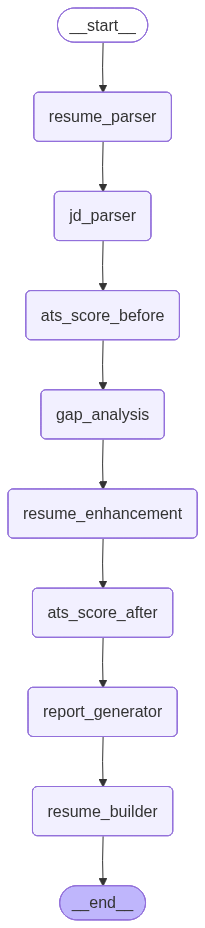

In [ ]:
from IPython.display import Image, display
graph_image = app.get_graph().draw_mermaid_png()
display(Image(graph_image))

# Testing End-to-End Pipeline

In [ ]:
#  Prepare the initial state 
initial_state = {
    "resume_text": resume_text,   
    "jd_text": SAMPLE_JD,         
}

print("Starting the Resume-to-JD Gap Analyzer pipeline...")
print("_" * 60)

start_time = time.time()

#  Runing the full LangGraph pipeline 
final_state = app.invoke(initial_state)

elapsed = time.time() - start_time
print("\n" + "_" * 60)
print(f" Pipeline complete in {elapsed:.1f} seconds!")


Starting the Resume-to-JD Gap Analyzer pipeline...
  LLM: Groq (llama-3.3-70b-versatile)
  Calls: 8 total | Rate limit: 30/min
____________________________________________________________
  ✅ Resume parsed: 45 skills, 3 projects, 1 experience entries, 1 education entries, 5 certifications
  ✅ JD parsed: 10 required skills, 13 preferred skills, 7 responsibilities

  📊 ATS Score (BEFORE optimization): 73.0/100
     ├─ Skill Match:       80.0
     ├─ Keyword Coverage:  70.0
     ├─ Experience Alignment:  40.0
     ├─ Resume Quality:    90.0
     └─ Project Relevance: 95.0


RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `llama-3.3-70b-versatile` in organization `org_01kvwavvygfqsare33ns7rnzbe` service tier `on_demand` on tokens per day (TPD): Limit 100000, Used 95357, Requested 4907. Please try again in 3m48.096s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

# Return Final Result

In [ ]:
#  Extract the final report 
report = final_state["final_report"]

print("FINAL REPORT")

#  Executive Summary 
print("\n EXECUTIVE SUMMARY")
print("─" * 60)
print(textwrap.fill(report.get("executive_summary", "N/A"), width=60))

#  ATS Score Comparison 
print("\n\n ATS SCORE COMPARISON")
print("─" * 60)
score_before = report["ats_score_before"]
score_after = report["ats_score_after"]
improvement = report["improvement_percentage"]



print(f"\n  BEFORE: {score_before:5.1f}/100")
print(f"  AFTER:  {score_after:5.1f}/100")
print(f"\n   Improvement: {improvement:+.1f}%")

FINAL REPORT

 EXECUTIVE SUMMARY
────────────────────────────────────────────────────────────
This report provides a comprehensive analysis of your
resume, highlighting areas of strength and weakness. With a
9.2% improvement in ATS score, you have made significant
progress in showcasing your skills and experiences. However,
there are still opportunities for growth, particularly in
gaining hands-on experience with PyTorch, REST API, and
Docker. By following the recommendations outlined in this
report, you can further enhance your resume, increase your
competitiveness, and improve your chances of landing your
target role. Remember to stay focused, persistent, and
always be open to learning and growth.


📊 ATS SCORE COMPARISON
────────────────────────────────────────────────────────────

  BEFORE:  65.5/100
  AFTER:   71.5/100

   Improvement: +9.2%


In [ ]:
#  Skill Match Analysis 
skill_analysis = report.get("skill_match_analysis", {})
matched = skill_analysis.get("matched", [])
missing = skill_analysis.get("missing", [])

print("\n\n SKILL MATCH ANALYSIS")
print("─" * 60)

print(f"\n  ✅ Matched Skills ({len(matched)}):")
for skill in matched:
    print(f"     • {skill}")

print(f"\n  ❌ Missing Skills ({len(missing)}):")
for skill in missing:
    print(f"     • {skill}")

#  Missing Keywords 
missing_kw = report.get("missing_keywords", [])
print(f"\n\n MISSING KEYWORDS ({len(missing_kw)}):")
print("─" * 60)
for kw in missing_kw:
    print(f"     • {kw}")



 SKILL MATCH ANALYSIS
────────────────────────────────────────────────────────────

  ✅ Matched Skills (7):
     • Python
     • TensorFlow
     • Scikit-learn
     • Deep Learning
     • Natural Language Processing
     • SQL
     • Git

  ❌ Missing Skills (3):
     • PyTorch
     • REST API
     • Docker


 MISSING KEYWORDS (12):
────────────────────────────────────────────────────────────
     • MLOps
     • MLflow
     • Kubeflow
     • Cloud platforms
     • AWS SageMaker
     • GCP Vertex AI
     • Azure ML
     • LLM
     • Kubernetes
     • CI/CD pipelines
     • Model drift
     • Code reviews


In [ ]:
#  Recommendations 
recs = report.get("recommendations", [])

print("\n\n RECOMMENDATIONS")
print("─" * 60)

for i, rec in enumerate(recs, 1):
    print(f"\n  {i}. {textwrap.fill(rec, width=55, subsequent_indent='     ')}")



 RECOMMENDATIONS
────────────────────────────────────────────────────────────

  1. Gain hands-on experience with PyTorch, a required skill
     for the target role, by working on projects or
     taking online courses

  2. Develop skills in REST API and Docker, which are
     essential for the position, by participating in
     relevant projects or attending workshops

  3. Familiarize yourself with MLOps, MLflow, and Kubeflow,
     which are preferred skills, by reading industry
     blogs, attending webinars, or taking online
     courses

  4. Explore cloud platforms, such as AWS SageMaker, GCP
     Vertex AI, or Azure ML, to broaden your skill set
     and increase your competitiveness

  5. Learn about CI/CD pipelines, code reviews, and model
     drift to improve your collaboration and code
     quality skills, which are crucial for the target
     role

  6. Consider taking courses or attending workshops to learn
     about LLM, Kubernetes, and other relevant
     technologi

In [ ]:
#  Export full results to JSON 

output_data = {
    "pipeline_info": {
        "llm": "Groq (llama-3.3-70b-versatile)",
        "total_calls": 8,
    },
    "resume_data": final_state.get("resume_data"),
    "jd_data": final_state.get("jd_data"),
    "ats_score_before": final_state.get("ats_score_before"),
    "ats_score_after": final_state.get("ats_score_after"),
    "gap_analysis": final_state.get("gap_analysis"),
    "optimized_resume": final_state.get("optimized_resume"),
    "final_report": final_state.get("final_report"),
    "optimized_latex": final_state.get("optimized_latex"),
}

output_path = "gap_analysis_results.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(output_data, f, indent=2, ensure_ascii=False)

print(f"💾 Full results exported to: {output_path}")
print(f"   File size: {os.path.getsize(output_path):,} bytes")


💾 Full results exported to: gap_analysis_results.json
   File size: 26,793 bytes


# Further Improvements:
1. API Key Integration: Added a feature/tab in the Streamlit UI to allow users to input their OpenAI or Gemini API keys directly.
2. Tailored Executive Summary: Enabled the AI agent to rewrite the user's executive summary to align precisely with the target job description.
3. Match Score Visualization: Implemented a UI metric that rates a candidate's job fit on a scale from 0 to 5.
4. Performance Optimization: Leveraged LangGraph to execute multiple AI agents in parallel, significantly reducing the total time required to analyze data and generate the tailored resume.

        ├──► Node 1: Parse Resume (resume_data) ───┐
        ├──► Node 2: Parse JD (jd_data) ───────────┘──► (Executed in Parallel)
